In [ ]:
!pip install optuna


In [ ]:
import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,mean_absolute_percentage_error
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import optuna

In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
df = pd.read_csv('Yemen_Rainfall_1982_2025.csv')
df

NameError: name 'pd' is not defined

# New Section

In [ ]:
df = df.drop(['Unnamed: 0', 'adm_level', 'adm_id','rfq','n_pixels','r1q', 'r3q','r1h_avg','rfh_avg','r3h_avg','version'], axis=1, errors='ignore')

df = df.sort_values(by=['PCODE', 'date','year','month','dekad']).reset_index(drop=True)

df.head()

,date,PCODE,rfh,r1h,r3h,month,dekad,year
0,1982-01-01,0,1.000000,4.000000,9.833333,1,1,1982
1,1982-01-11,0,3.000000,6.000000,12.000000,1,11,1982
2,1982-01-21,0,1.000000,5.000000,12.000000,1,21,1982
3,1982-02-01,0,1.000000,5.000000,12.000000,2,1,1982
4,1982-02-11,0,3.583333,5.583333,14.583333,2,11,1982


In [ ]:
lags = [1, 2, 3, 6, 12]

def create_lags(df):
    df = df.sort_values(['PCODE','year','month','dekad'])

    for lag in [1,2,3,6,12]:
        df[f'rfh_lag_{lag}'] = df.groupby('PCODE')['rfh'].shift(lag)

    return df

df = create_lags(df)
df = df.dropna().reset_index(drop=True)
df['PCODE'] = df['PCODE'].astype('category').cat.codes

In [ ]:
 # Cyclical month encoding
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['dekad_sin'] = np.sin(2 * np.pi * df['dekad']/3)
df['dekad_cos'] = np.cos(2 * np.pi * df['dekad']/3)

df.head()

,date,PCODE,rfh,r1h,r3h,month,dekad,year,rfh_lag_1,rfh_lag_2,rfh_lag_3,rfh_lag_6,rfh_lag_12,month_sin,month_cos,dekad_sin,dekad_cos
0,1982-05-01,0,11.666667,19.708334,37.625000,5,1,1982,3.333333,4.708334,4.041666,1.000000,1.000000,5.000000e-01,-0.866025,8.660254e-01,-0.5
1,1982-05-11,0,14.416667,29.416668,48.458336,5,11,1982,11.666667,3.333333,4.708334,0.291667,3.000000,5.000000e-01,-0.866025,-8.660254e-01,-0.5
2,1982-05-21,0,7.125000,33.208336,54.583336,5,21,1982,14.416667,11.666667,3.333333,8.000000,1.000000,5.000000e-01,-0.866025,-1.714506e-15,1.0
3,1982-06-01,0,1.333333,22.875002,54.916668,6,1,1982,7.125000,14.416667,11.666667,4.041666,1.000000,1.224647e-16,-1.000000,8.660254e-01,-0.5
4,1982-06-11,0,0.000000,8.458333,54.625000,6,11,1982,1.333333,7.125000,14.416667,4.708334,3.583333,1.224647e-16,-1.000000,-8.660254e-01,-0.5


In [ ]:
num_features = [
    'rfh','r1h','r3h',
    'month_sin','month_cos',
    'dekad_sin','dekad_cos',
    'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_3','rfh_lag_6','rfh_lag_12',
]
cat_feature = 'PCODE'

# 1 Log transform

df_log = df.copy()

cols = ['rfh', 'r1h', 'r3h']
for col in cols:
    df_log[col] = np.log1p(df_log[col])


# 2 minmax
scaler = MinMaxScaler()
df[num_features] = scaler.fit_transform(df[num_features])
num_pcodes = df['PCODE'].nunique()
print("Number of unique PCodes:", num_pcodes)


#  3 Split
train_df = df[df['date'] <= '2015-12-31'].copy()
val_df   = df[(df['date'] > '2015-12-31') & (df['date'] <= '2020-12-31')].copy()
test_df  = df[df['date'] > '2020-12-31'].copy()

Number of unique PCodes: 318


In [ ]:
def create_sequences(df, num_features, cat_feature, window=36):
    X_num, X_cat, y = [], [], []

    for pcode in df[cat_feature].unique():
        df_sub = df[df[cat_feature] == pcode]

        num_data = df_sub[num_features].values
        cat_data = df_sub[cat_feature].values

        for i in range(len(num_data) - window):
            X_num.append(num_data[i:i+window])
            X_cat.append(cat_data[i:i+window])
            y.append(num_data[i+window][0])  # predict rfh

    return np.array(X_num), np.array(X_cat), np.array(y)

In [ ]:
X_train_num, X_train_cat, y_train = create_sequences(train_df, num_features, cat_feature)
X_val_num, X_val_cat, y_val = create_sequences(val_df, num_features, cat_feature)
X_test_num, X_test_cat, y_test = create_sequences(test_df, num_features, cat_feature)

In [ ]:
def to_loader(X_num, X_cat, y, batch_size=64):
    dataset = TensorDataset(
        torch.tensor(X_num, dtype=torch.float32),
        torch.tensor(X_cat, dtype=torch.long),   # categorical
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=True
    )

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, num_features, num_pcodes, embed_dim, hidden_size, num_layers, dropout):
        super().__init__()

        self.embedding = nn.Embedding(num_pcodes, embed_dim)

        self.lstm = nn.LSTM(
            input_size=num_features + embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x_num, x_cat):

        x_cat = self.embedding(x_cat)        # (B, T, embed_dim)

        x = torch.cat([x_num, x_cat], dim=-1)

        out, _ = self.lstm(x)

        out = out[:, -1, :]

        return self.fc(out).squeeze()

In [ ]:
def objective(trial):

    hidden_size = trial.suggest_int("hidden_size", 64, 128)
    num_layers  = trial.suggest_int("num_layers", 2, 3)
    dropout     = trial.suggest_float("dropout", 0.1, 0.3)
    lr          = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
    batch_size  = trial.suggest_categorical("batch_size", [64, 128])
    embed_dim   = trial.suggest_int("embed_dim", 4, 16)


    train_loader = to_loader(X_train_num, X_train_cat, y_train, batch_size)
    val_loader   = to_loader(X_val_num, X_val_cat, y_val, batch_size)

    model = LSTMModel(
        num_features=X_train_num.shape[2],
        num_pcodes=num_pcodes,
        embed_dim=embed_dim,
        hidden_size=hidden_size,
        num_layers=num_layers,
        dropout=dropout
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    #  TRAIN
    for epoch in range(30):
        model.train()

        for xb_num, xb_cat, yb in train_loader:
            xb_num = xb_num.to(device)
            xb_cat = xb_cat.to(device)
            yb     = yb.to(device)

            optimizer.zero_grad()

            pred = model(xb_num, xb_cat)
            loss = loss_fn(pred, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

    #  Validation
    model.eval()
    preds, actuals = [], []

    with torch.no_grad():
        for xb_num, xb_cat, yb in val_loader:
            xb_num = xb_num.to(device)
            xb_cat = xb_cat.to(device)
            yb = yb.to(device)
            pred = model(xb_num, xb_cat)

            preds.extend(pred.cpu().numpy())
            actuals.extend(yb.cpu().numpy())

    mse = mean_squared_error(actuals, preds)

    return mse

In [ ]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

print("Best Params:", study.best_params)
print("Best Validation Loss:", study.best_value)


[I 2026-09-21 15:32:31,086] A new study created in memory with name: no-name-eb995087-7c18-49d1-863a-f0723b2461bf
[I 2026-09-21 15:40:08,943] Trial 0 finished with value: 0.0020711124438168153 and parameters: {'hidden_size': 121, 'num_layers': 2, 'dropout': 0.15997872134981775, 'lr': 0.0001361195086798098, 'batch_size': 128, 'embed_dim': 14}. Best is trial 0 with value: 0.0020711124438168153.
[I 2026-09-21 15:47:30,000] Trial 1 finished with value: 0.001878921617141003 and parameters: {'hidden_size': 74, 'num_layers': 3, 'dropout': 0.11620338749261468, 'lr': 0.00010413665008822641, 'batch_size': 128, 'embed_dim': 9}. Best is trial 1 with value: 0.001878921617141003.
[I 2026-09-21 15:54:53,926] Trial 2 finished with value: 0.0021760712745283496 and parameters: {'hidden_size': 123, 'num_layers': 2, 'dropout': 0.23864490196674562, 'lr': 0.00010349431296679233, 'batch_size': 128, 'embed_dim': 7}. Best is trial 1 with value: 0.001878921617141003.
[I 2026-09-21 16:06:13,698] Trial 3 finished

Best Params: {'hidden_size': 67, 'num_layers': 3, 'dropout': 0.1794296199602189, 'lr': 0.00015219250170710194, 'batch_size': 128, 'embed_dim': 12}
Best Validation Loss: 0.0018459262990176447


In [ ]:
best = study.best_params

model = LSTMModel(
    num_features=X_train_num.shape[2],
    num_pcodes=num_pcodes,
    embed_dim=best['embed_dim'],
    hidden_size=best['hidden_size'],
    num_layers=best['num_layers'],
    dropout=best['dropout']
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=best['lr'])
loss_fn = nn.MSELoss()

train_loader = to_loader(X_train_num, X_train_cat, y_train, best['batch_size'])
val_loader   = to_loader(X_val_num, X_val_cat, y_val, best['batch_size'])
test_loader  = to_loader(X_test_num, X_test_cat, y_test, best['batch_size'])

In [ ]:
best_val_loss = float('inf')

for epoch in range(50):

    model.train()
    train_loss = 0

    for xb_num, xb_cat, yb in train_loader:
        xb_num = xb_num.to(device)
        xb_cat = xb_cat.to(device)
        yb     = yb.to(device)

        optimizer.zero_grad()

        pred = model(xb_num, xb_cat)
        loss = loss_fn(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)

    # VALIDATION
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for xb_num, xb_cat, yb in val_loader:
            xb_num = xb_num.to(device)
            xb_cat = xb_cat.to(device)
            yb     = yb.to(device)
            pred = model(xb_num, xb_cat)
            loss = loss_fn(pred, yb)
            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(f"Epoch {epoch+1}: Train={train_loss:.4f}, Val={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "lstm_model.pth")

Epoch 1: Train=0.0014, Val=0.0039
Epoch 2: Train=0.0013, Val=0.0032
Epoch 3: Train=0.0011, Val=0.0024
Epoch 4: Train=0.0010, Val=0.0021
Epoch 5: Train=0.0009, Val=0.0018
Epoch 6: Train=0.0009, Val=0.0017
Epoch 7: Train=0.0008, Val=0.0017
Epoch 8: Train=0.0008, Val=0.0017
Epoch 9: Train=0.0008, Val=0.0018
Epoch 10: Train=0.0008, Val=0.0018
Epoch 11: Train=0.0008, Val=0.0018
Epoch 12: Train=0.0008, Val=0.0018
Epoch 13: Train=0.0007, Val=0.0019
Epoch 14: Train=0.0007, Val=0.0019
Epoch 15: Train=0.0007, Val=0.0020
Epoch 16: Train=0.0007, Val=0.0021
Epoch 17: Train=0.0007, Val=0.0022
Epoch 18: Train=0.0007, Val=0.0021
Epoch 19: Train=0.0007, Val=0.0021
Epoch 20: Train=0.0007, Val=0.0021
Epoch 21: Train=0.0006, Val=0.0021
Epoch 22: Train=0.0006, Val=0.0021
Epoch 23: Train=0.0006, Val=0.0021
Epoch 24: Train=0.0006, Val=0.0020
Epoch 25: Train=0.0006, Val=0.0020
Epoch 26: Train=0.0006, Val=0.0020
Epoch 27: Train=0.0006, Val=0.0020
Epoch 28: Train=0.0006, Val=0.0020
Epoch 29: Train=0.0005, Val=0

In [ ]:
model.load_state_dict(torch.load("lstm_model.pth"))
model.eval()
preds, actuals = [], []

with torch.no_grad():
    for xb_num, xb_cat, yb in test_loader:
        xb_num = xb_num.to(device)
        xb_cat = xb_cat.to(device)
        yb     = yb.to(device)
        pred = model(xb_num, xb_cat)

        preds.extend(pred.cpu().numpy())
        actuals.extend(yb.cpu().numpy())



In [ ]:
mse = mean_squared_error(actuals, preds)
mae = mean_absolute_error(actuals, preds)
r2  = r2_score(actuals, preds)

print("MSE:", mse)
print("MAE:", mae)
print("R2 :", r2)

MSE: 0.0036959050196308436
MAE: 0.026160412171336005
R2 : 0.46225749237623526


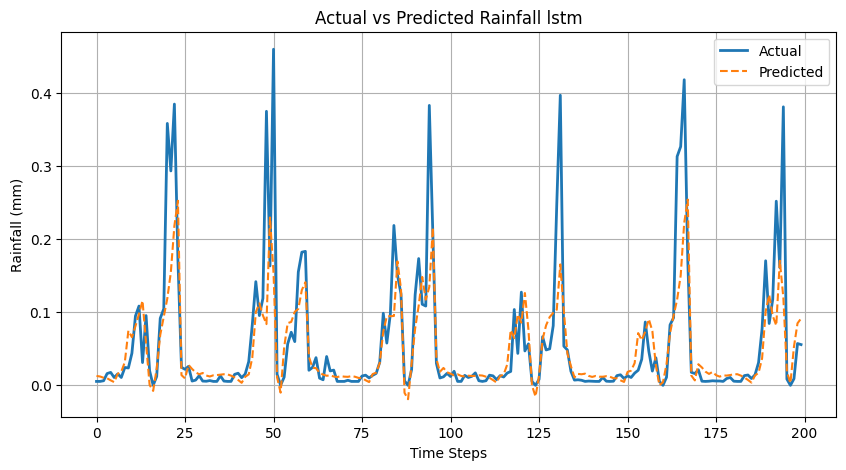

In [ ]:
plt.figure(figsize=(10,5))

# plt.plot(actuals[:200], label="Actual")
# plt.plot(preds[:200], label="Predicted")
plt.plot(actuals[:200], label="Actual", linewidth=2)
plt.plot(preds[:200], label="Predicted", linestyle='--')

plt.xlabel("Time Steps")          # X-axis label
plt.ylabel("Rainfall (mm)")       # Y-axis label
plt.title("Actual vs Predicted Rainfall lstm")  # Title

plt.legend()
plt.grid(True)

plt.show()

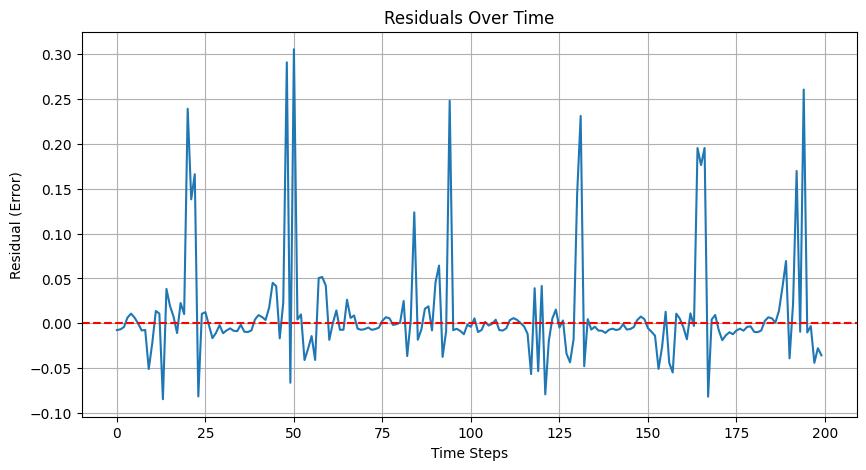

In [ ]:
residuals = np.array(actuals) - np.array(preds)

plt.figure(figsize=(10,5))
plt.plot(residuals[:200])

plt.axhline(0, color='r', linestyle='--')  # zero line

plt.xlabel("Time Steps")
plt.ylabel("Residual (Error)")
plt.title("Residuals Over Time")

plt.grid(True)
plt.show()

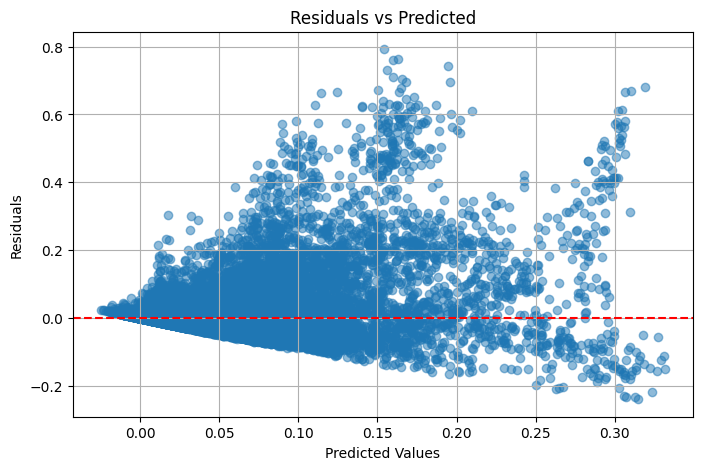

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(preds, residuals, alpha=0.5)

plt.axhline(0, color='r', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")

plt.grid(True)
plt.show()

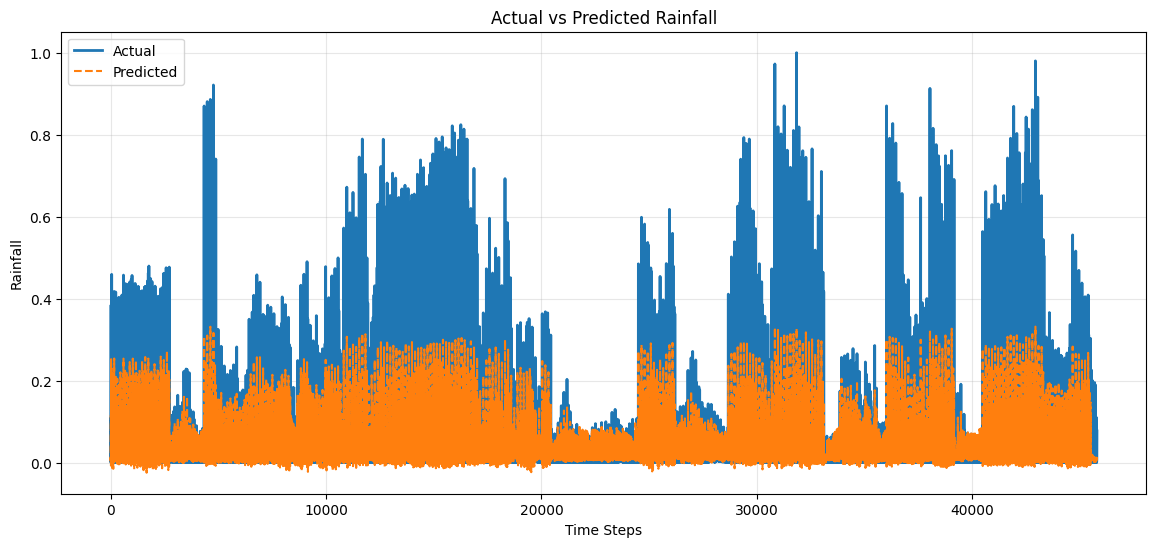

In [ ]:
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

plt.figure(figsize=(14,6))

plt.plot(y_true, label="Actual", linewidth=2)
plt.plot(y_pred, label="Predicted", linestyle='--')

plt.title("Actual vs Predicted Rainfall")
plt.xlabel("Time Steps")
plt.ylabel("Rainfall")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("actual_vs_predicted_lstm.png", dpi=300)
plt.show()

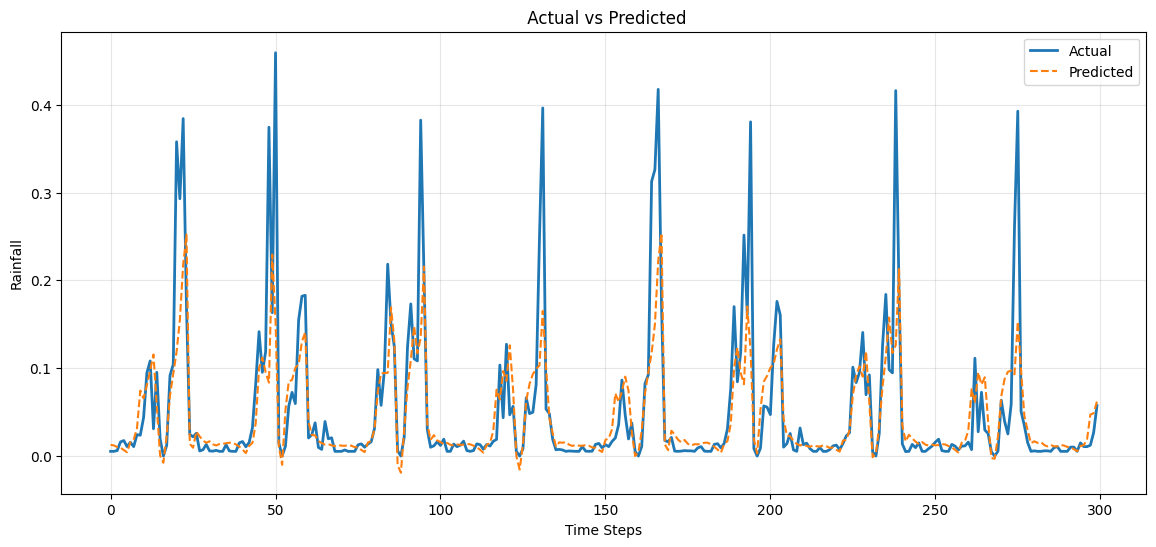

In [ ]:
start, end = 0, 300

plt.figure(figsize=(14,6))

plt.plot(y_true[start:end], label="Actual", linewidth=2)
plt.plot(y_pred[start:end], label="Predicted", linestyle='--')

plt.title(" Actual vs Predicted")
plt.xlabel("Time Steps")
plt.ylabel("Rainfall")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("zoom_plot_lstm.png", dpi=300)
plt.show()

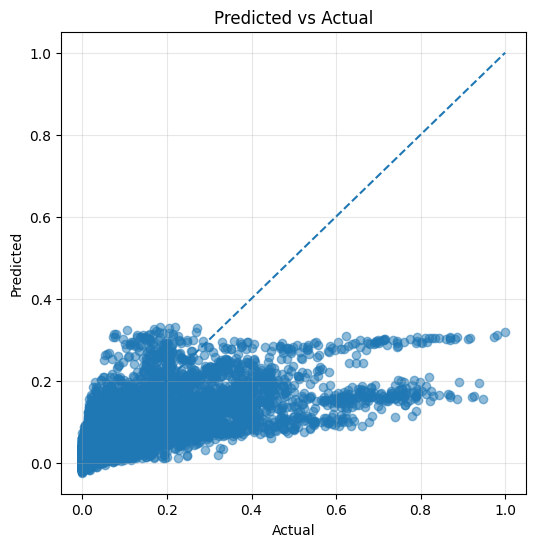

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(y_true, y_pred, alpha=0.5)

# perfect prediction line
plt.plot([y_true.min(), y_true.max()],
         [y_true.min(), y_true.max()],
         linestyle='--')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual")

plt.grid(alpha=0.3)

plt.savefig("scatter_plot_lstm.png", dpi=300)
plt.show()

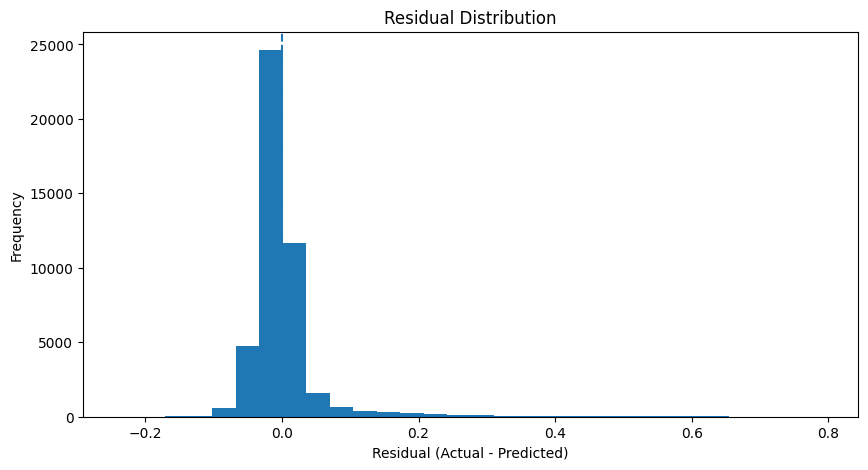

In [ ]:
residuals = y_true - y_pred

plt.figure(figsize=(10,5))

plt.hist(residuals, bins=30)
plt.axvline(0, linestyle='--')

plt.title("Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.savefig("residual_plot_lstm.png", dpi=300)
plt.show()

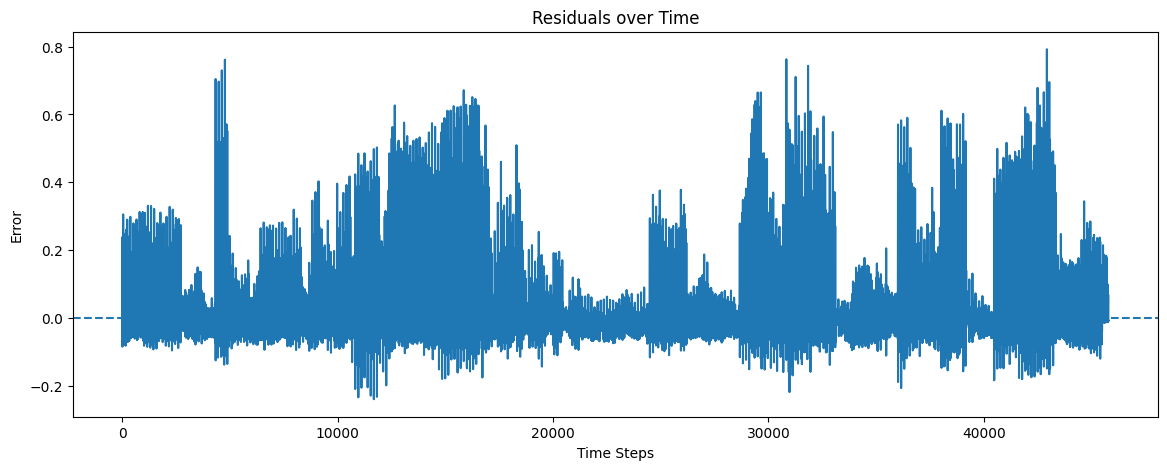

In [ ]:
plt.figure(figsize=(14,5))

plt.plot(residuals)

plt.axhline(0, linestyle='--')

plt.title("Residuals over Time")
plt.xlabel("Time Steps")
plt.ylabel("Error")

plt.savefig("residual_time_lstm.png", dpi=300)
plt.show()

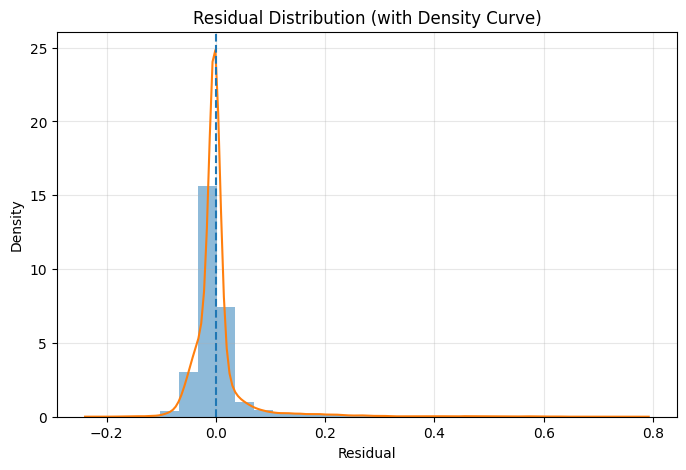

In [ ]:
from scipy.stats import gaussian_kde

density = gaussian_kde(residuals)
xs = np.linspace(residuals.min(), residuals.max(), 200)

plt.figure(figsize=(8,5))

plt.hist(residuals, bins=30, density=True, alpha=0.5)
plt.plot(xs, density(xs))

plt.axvline(0, linestyle='--')

plt.title("Residual Distribution (with Density Curve)")
plt.xlabel("Residual")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.savefig("residual_distribution_kde_lstm.png", dpi=300)
plt.show()

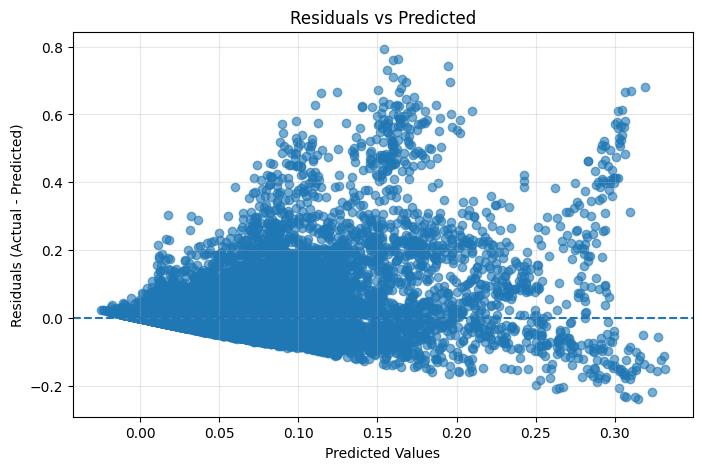

In [ ]:
# Convert to numpy
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals, alpha=0.6)

# Zero error line
plt.axhline(0, linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Predicted")

plt.grid(alpha=0.3)

plt.savefig("residual_vs_predicted_lstm.png", dpi=300)
plt.show()

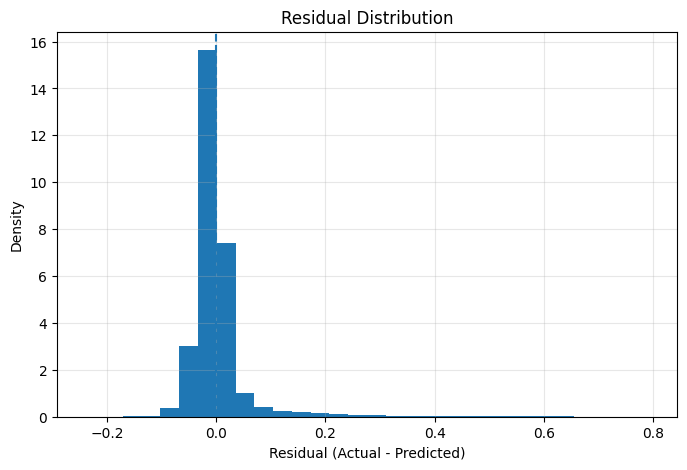

In [ ]:
# Convert to numpy
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(8,5))

plt.hist(residuals, bins=30, density=True)
plt.axvline(0, linestyle='--')

plt.title("Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.savefig("residual_distribution_gru.png", dpi=300)
plt.show()

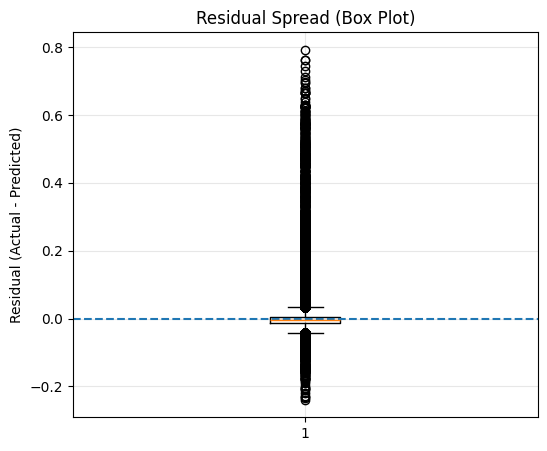

In [ ]:
# Convert
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(6,5))

plt.boxplot(residuals, vert=True)

# zero reference line
plt.axhline(0, linestyle='--')

plt.title("Residual Spread (Box Plot)")
plt.ylabel("Residual (Actual - Predicted)")

plt.grid(alpha=0.3)

plt.savefig("residual_boxplot_lstm.png", dpi=300)
plt.show()

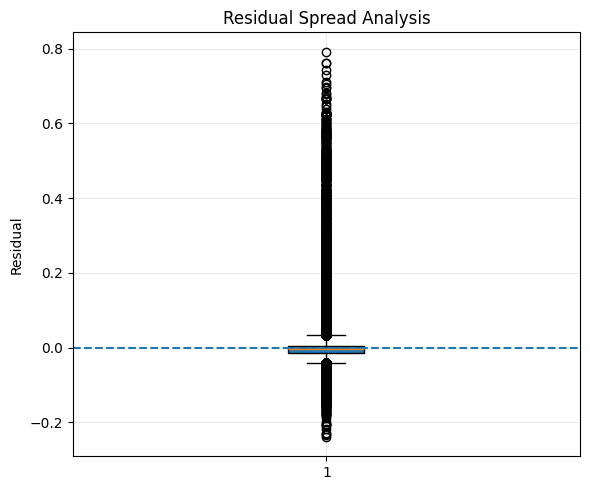

In [ ]:
plt.figure(figsize=(6,5))

plt.boxplot(
    residuals,
    vert=True,
    patch_artist=True   # filled box (cleaner look)
)

plt.axhline(0, linestyle='--')

plt.title("Residual Spread Analysis")
plt.ylabel("Residual")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("residual_boxplot_clean_lstm.png", dpi=300)
plt.show()

In [ ]:
results = pd.DataFrame({
    "actual": actuals,
    "pred": preds
})

results.to_csv("lstm_results.csv", index=False)

In [ ]:
lstm = pd.read_csv("lstm_results.csv")
lstm

,actual,pred
0,0.005370,0.012820
1,0.005370,0.012075
2,0.006265,0.010362
3,0.016110,0.009674
4,0.017677,0.006837
...,...,...
45787,0.028405,0.012105
45788,0.034341,0.012015
45789,0.041407,0.012250
45790,0.063594,0.011864
